Training data: (400, 2)
Testing data: (100, 2)

Training completed!
Final Training Loss: 0.031028914215710347


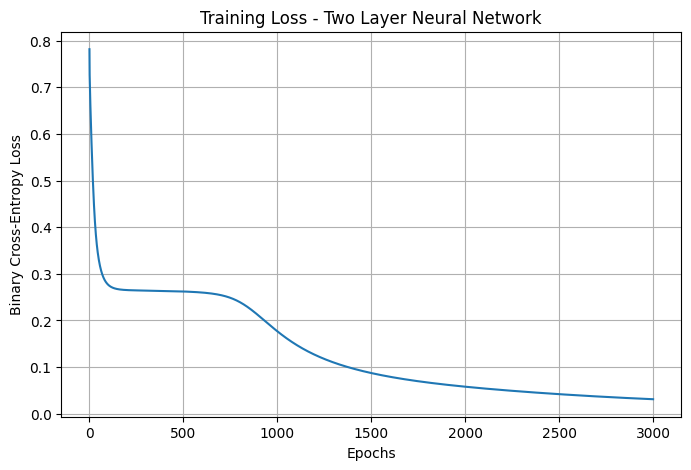


Test Accuracy: 100.0 %


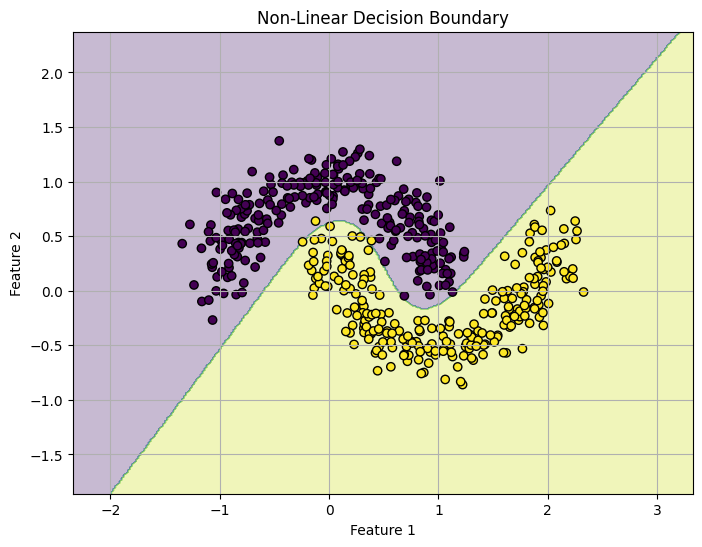


Gradient Verification
Analytical Gradient: -0.00025098840713955515
Numerical Gradient: -0.00025098840783499554
Difference: 6.95440395808572e-13

Experiment 8 Completed Successfully!


In [11]:
# EXPERIMENT 8: TWO-LAYER NEURAL NETWORK WITH BACKPROPAGATION

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

np.random.seed(42)

# --------------------------------------------------
# TASK 1: GENERATE TWO-MOONS DATASET
# --------------------------------------------------

X, y = make_moons(n_samples=500, noise=0.15, random_state=42)

y = y.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

# --------------------------------------------------
# TASK 1: INITIALISE WEIGHTS AND BIASES
# --------------------------------------------------

input_size = 2
hidden_size = 10
output_size = 1

W1 = np.random.randn(input_size, hidden_size) * np.sqrt(1/input_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, output_size) * np.sqrt(1/hidden_size)
b2 = np.zeros((1, output_size))

# --------------------------------------------------
# SIGMOID ACTIVATION
# --------------------------------------------------

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))

# --------------------------------------------------
# TASK 2: FORWARD PROPAGATION
# --------------------------------------------------

def forward(X, W1, b1, W2, b2):

    Z1 = np.dot(X, W1) + b1
    A1 = sigmoid(Z1)

    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)

    return Z1, A1, Z2, A2

# --------------------------------------------------
# LOSS FUNCTION: BINARY CROSS-ENTROPY
# --------------------------------------------------

def loss_function(y, predictions):

    predictions = np.clip(predictions, 1e-7, 1-1e-7)

    loss = -np.mean(
        y*np.log(predictions) +
        (1-y)*np.log(1-predictions)
    )

    return loss

# --------------------------------------------------
# TASK 3: BACKPROPAGATION USING CHAIN RULE
# --------------------------------------------------

def backward(X, y, A1, A2, W2):

    m = X.shape[0]

    # Output layer gradient
    dZ2 = A2 - y
    dW2 = np.dot(A1.T, dZ2) / m
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m

    # Hidden layer gradient
    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * A1 * (1-A1)

    dW1 = np.dot(X.T, dZ1) / m
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m

    return dW1, db1, dW2, db2

# --------------------------------------------------
# TASK 3: TRAIN NETWORK USING GRADIENT DESCENT
# --------------------------------------------------

learning_rate = 1.0
epochs = 3000

loss_history = []

for epoch in range(epochs):

    # Forward pass
    Z1, A1, Z2, A2 = forward(X_train, W1, b1, W2, b2)

    # Calculate loss
    loss = loss_function(y_train, A2)
    loss_history.append(loss)

    # Backward pass
    dW1, db1, dW2, db2 = backward(
        X_train, y_train, A1, A2, W2
    )

    # Update parameters
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

print("\nTraining completed!")
print("Final Training Loss:", loss_history[-1])

# --------------------------------------------------
# TASK 4: PLOT LOSS AGAINST EPOCHS
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.title("Training Loss - Two Layer Neural Network")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid()
plt.show()

# --------------------------------------------------
# TEST MODEL
# --------------------------------------------------

_, _, _, test_predictions = forward(
    X_test, W1, b1, W2, b2
)

predicted_classes = (test_predictions >= 0.5).astype(int)

accuracy = np.mean(predicted_classes == y_test) * 100

print("\nTest Accuracy:", round(accuracy, 2), "%")

# --------------------------------------------------
# TASK 5: PLOT NON-LINEAR DECISION BOUNDARY
# --------------------------------------------------

x_min, x_max = X[:, 0].min()-1, X[:, 0].max()+1
y_min, y_max = X[:, 1].min()-1, X[:, 1].max()+1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

_, _, _, grid_predictions = forward(
    grid, W1, b1, W2, b2
)

Z = (grid_predictions >= 0.5).astype(int)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(xx, yy, Z, alpha=0.3)

plt.scatter(
    X[:, 0], X[:, 1],
    c=y.ravel(), edgecolors='black'
)

plt.title("Non-Linear Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid()
plt.show()

# --------------------------------------------------
# TASK 5: NUMERICAL GRADIENT VERIFICATION
# --------------------------------------------------

# Calculate analytical gradient
_, A1, _, A2 = forward(X_train, W1, b1, W2, b2)

dW1, db1, dW2, db2 = backward(
    X_train, y_train, A1, A2, W2
)

# Select one weight
i, j = 0, 0

original_weight = W1[i, j]
epsilon = 1e-5

# Loss with weight increased
W1[i, j] = original_weight + epsilon

_, _, _, pred_plus = forward(
    X_train, W1, b1, W2, b2
)

loss_plus = loss_function(y_train, pred_plus)

# Loss with weight decreased
W1[i, j] = original_weight - epsilon

_, _, _, pred_minus = forward(
    X_train, W1, b1, W2, b2
)

loss_minus = loss_function(y_train, pred_minus)

# Restore weight
W1[i, j] = original_weight

# Numerical gradient
numerical_gradient = (
    loss_plus - loss_minus
) / (2*epsilon)

analytical_gradient = dW1[i, j]

print("\nGradient Verification")

print("Analytical Gradient:",
      analytical_gradient)

print("Numerical Gradient:",
      numerical_gradient)

print("Difference:",
      abs(analytical_gradient - numerical_gradient))

# --------------------------------------------------
# FINAL RESULT
# --------------------------------------------------

print("\nExperiment 8 Completed Successfully!")